In [7]:
import itertools
dataJarak=[
    [0,10,15,20],
    [10,0,35,25],
    [15,35,0,30],
    [20,25,30,0]
]
n = len(dataJarak)
kota=range(n)
minpath=None
minCost=float('inf')

for p in itertools.permutations(kota[1:]):
  path=(0,)+p+(0,)
  cost=sum(dataJarak[path[i]][path[i+1]] for i in range(len(path)-1))
  if cost<minCost:
    minCost=cost
    minPath=path
print(minPath)
print(minCost)

(0, 1, 3, 2, 0)
80


(0, 1, 3, 2, 0)
80


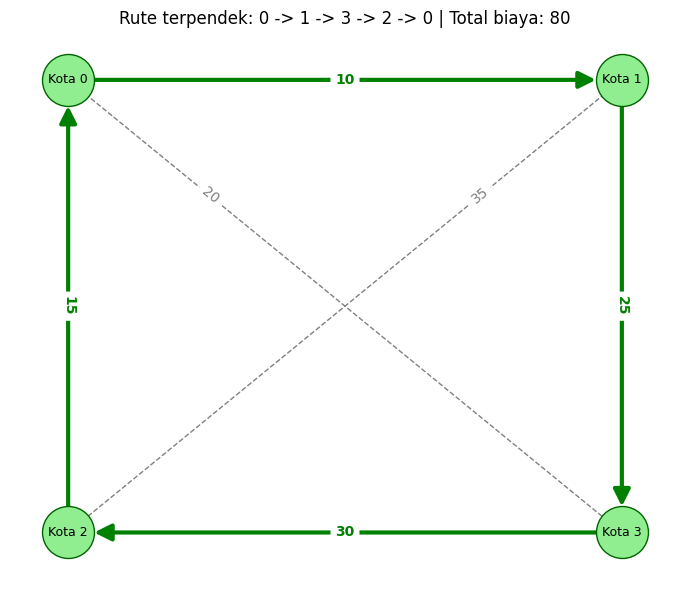

In [8]:
import itertools
import networkx as nx
import matplotlib.pyplot as plt

dataJarak = [
    [0, 10, 15, 20],
    [10, 0, 35, 25],
    [15, 35, 0, 30],
    [20, 25, 30, 0]
]
n = len(dataJarak)
kota = range(n)
minPath = None
minCost = float('inf')

for p in itertools.permutations(kota[1:]):
    path = (0,) + p + (0,)
    cost = sum(dataJarak[path[i]][path[i + 1]] for i in range(len(path) - 1))
    if cost < minCost:
        minCost = cost
        minPath = path

print(minPath)
print(minCost)

G = nx.Graph()
for i in range(n):
    for j in range(i + 1, n):
        G.add_edge(i, j, weight=dataJarak[i][j])

pos = {0: (0, 1), 1: (1, 1), 2: (0, 0), 3: (1, 0)}

rute_edges = [(minPath[i], minPath[i + 1]) for i in range(len(minPath) - 1)]
D = nx.DiGraph()
D.add_edges_from(rute_edges)

rute_set = {frozenset(e) for e in rute_edges}
edge_lain = [(u, v) for u, v in G.edges() if frozenset((u, v)) not in rute_set]
edge_rute = [(u, v) for u, v in G.edges() if frozenset((u, v)) in rute_set]

plt.figure(figsize=(7, 6))
nx.draw_networkx_nodes(G, pos, node_size=1400, node_color="lightgreen", edgecolors="darkgreen")
nx.draw_networkx_labels(G, pos, labels={i: f"Kota {i}" for i in G.nodes()}, font_size=9)
nx.draw_networkx_edges(G, pos, edgelist=edge_lain, edge_color="gray", style="dashed", width=1)
nx.draw_networkx_edges(D, pos, edge_color="green", width=3, arrows=True, arrowstyle="-|>", arrowsize=25, node_size=1400)

label_rute = {(u, v): G[u][v]["weight"] for u, v in edge_rute}
label_lain = {(u, v): G[u][v]["weight"] for u, v in edge_lain}
nx.draw_networkx_edge_labels(G, pos, edge_labels=label_rute, label_pos=0.5, font_color="green", font_weight="bold")
nx.draw_networkx_edge_labels(G, pos, edge_labels=label_lain, label_pos=0.25, font_color="gray")

plt.title(f"Rute terpendek: {' -> '.join(map(str, minPath))} | Total biaya: {minCost}")
plt.axis("off")
plt.tight_layout()
plt.show()